### Import necessary libraries

In [1]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import randint, uniform, loguniform
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    accuracy_score,
    roc_auc_score,
    recall_score,
    f1_score,
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import kagglehub
import pickle
import os

### Download data

In [2]:
path = kagglehub.dataset_download("miadul/credit-card-fraud-detection-dataset")

print(path)

/home/mz/.cache/kagglehub/datasets/miadul/credit-card-fraud-detection-dataset/versions/1


In [3]:
data = pd.read_csv(os.path.join(path, "credit_card_fraud_10k.csv"), index_col="transaction_id")

data.head()

,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
transaction_id,,,,,,,,,
1,84.47,22,Electronics,0,0,66,3,40,0
2,541.82,3,Travel,1,0,87,1,64,0
3,237.01,17,Grocery,0,0,49,1,61,0
4,164.33,4,Grocery,0,1,72,3,34,0
5,30.53,15,Food,0,0,79,0,44,0


In [4]:
data.shape

(10000, 9)

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 1 to 10000
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   amount               10000 non-null  float64
 1   transaction_hour     10000 non-null  int64  
 2   merchant_category    10000 non-null  str    
 3   foreign_transaction  10000 non-null  int64  
 4   location_mismatch    10000 non-null  int64  
 5   device_trust_score   10000 non-null  int64  
 6   velocity_last_24h    10000 non-null  int64  
 7   cardholder_age       10000 non-null  int64  
 8   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 703.3 KB


## EDA + Feature Engineering

### Helper functions

In [6]:
def check_distribution(data, title, xlabel="", color="blue", ylabel="Number of data points"):
    plt.figure(figsize=(12, 8))
    fig = sns.histplot(data, kde=True, color=color)
    plt.title(title)
    fig.set_xlabel(xlabel)
    fig.set_ylabel(ylabel)
    plt.show()

def check_counts(data, title, xlabel="", color="blue", ylabel="Number of data points"):
    plt.figure(figsize=(12,8))
    fig = sns.countplot(x=data, color=color)
    fig.set_title(title)
    fig.set_xlabel(xlabel)
    fig.set_ylabel(ylabel)
    plt.show()

### Check amount distributions

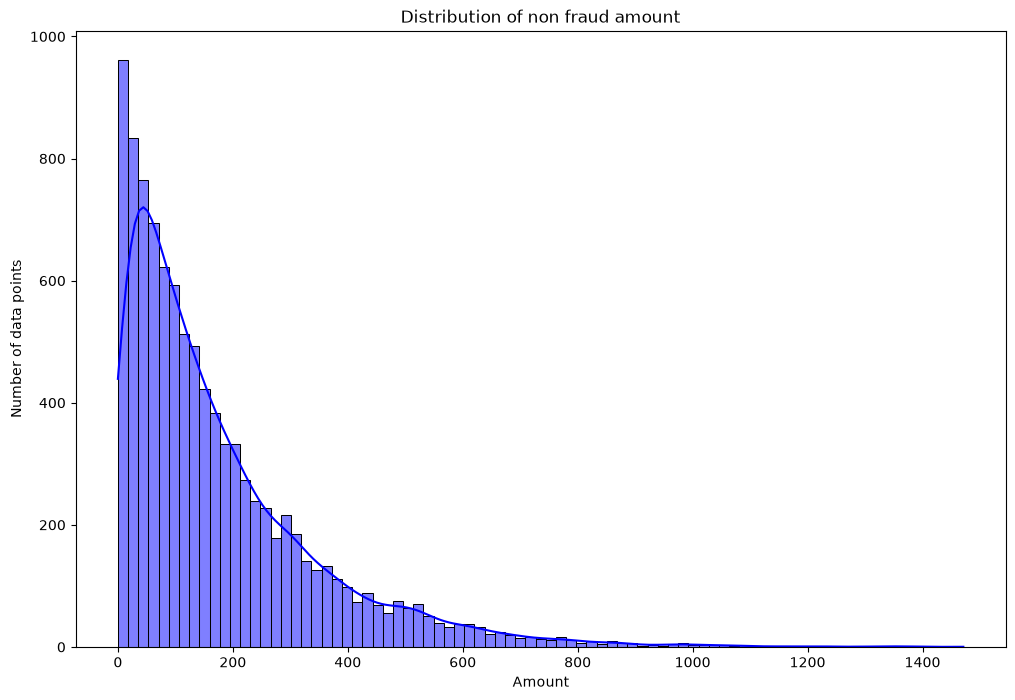

In [7]:
check_distribution(
    data=data.loc[data["is_fraud"] == 0, "amount"],
    title="Distribution of non fraud amount",
    xlabel="Amount",
    color="blue",
)

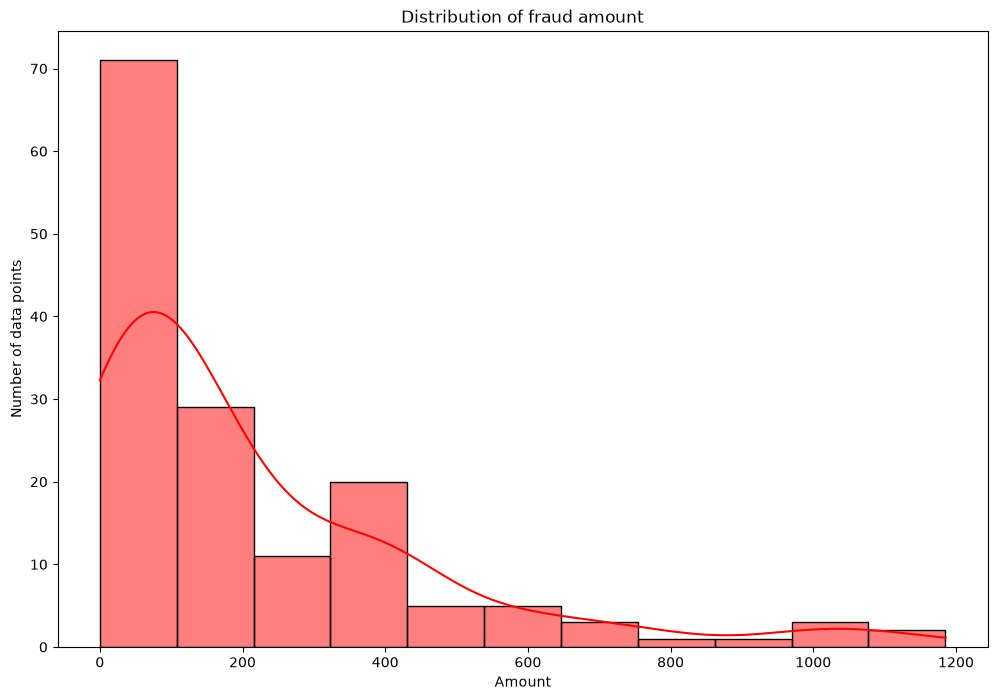

In [8]:
check_distribution(
    data=data.loc[data["is_fraud"] == 1, "amount"],
    title="Distribution of fraud amount",
    xlabel="Amount",
    color="red",
)

### Check transaction hours

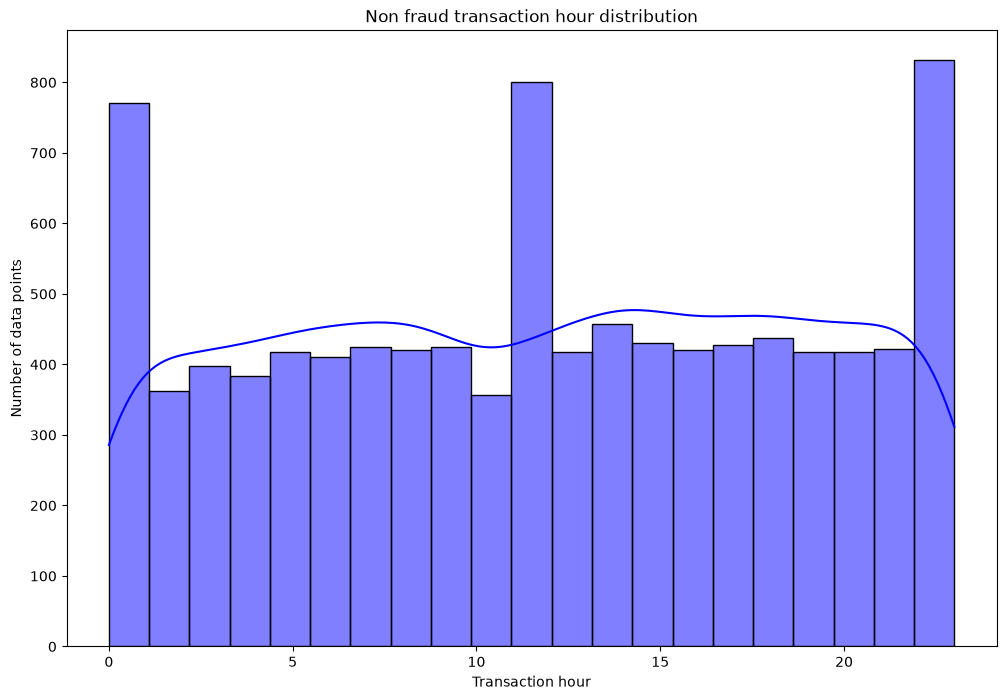

In [9]:
check_distribution(
    data=data.loc[data["is_fraud"] == 0, "transaction_hour"],
    title="Non fraud transaction hour distribution",
    xlabel="Transaction hour",
    color="blue",
)

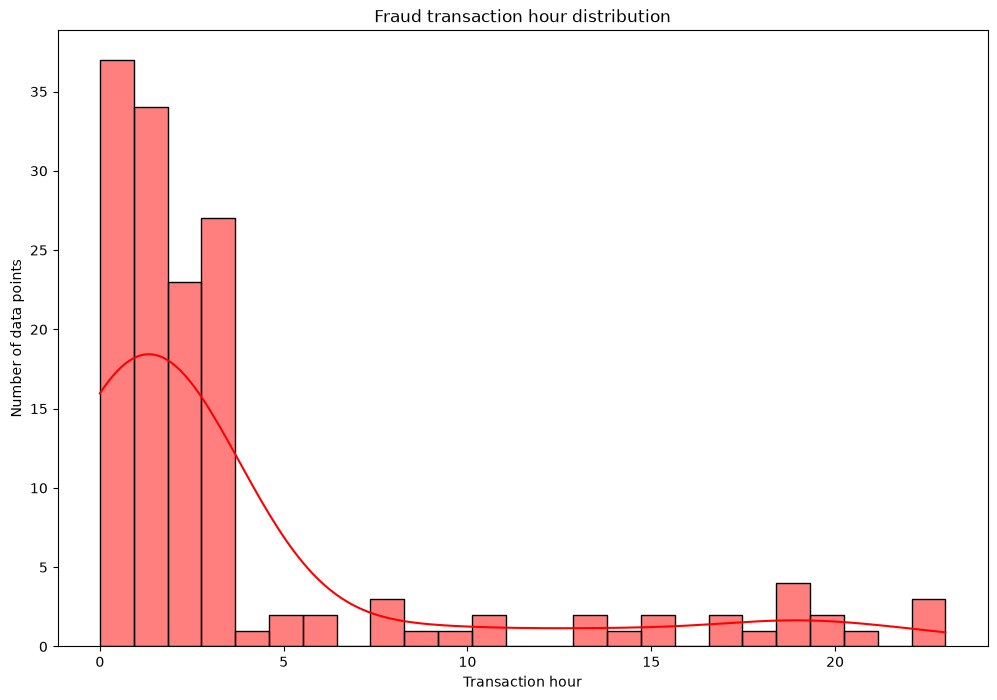

In [10]:
check_distribution(
    data=data.loc[data["is_fraud"] == 1, "transaction_hour"],
    title="Fraud transaction hour distribution",
    xlabel="Transaction hour",
    color="red",
)

#### Most fraudulent transaction happens in nighttime

In [11]:
data["nighttime_transaction"] = (data["transaction_hour"] <= 6).astype(int)

### Check categories

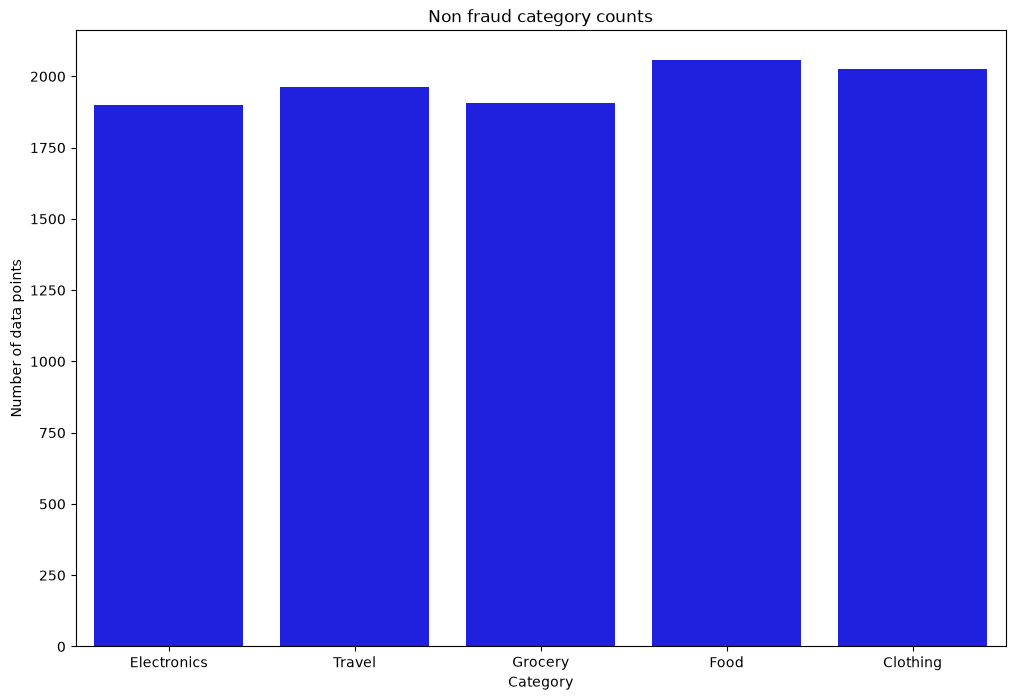

In [12]:
check_counts(
    data=data.loc[data["is_fraud"] == 0, "merchant_category"], 
    title="Non fraud category counts", 
    xlabel="Category",
    color="blue",
)

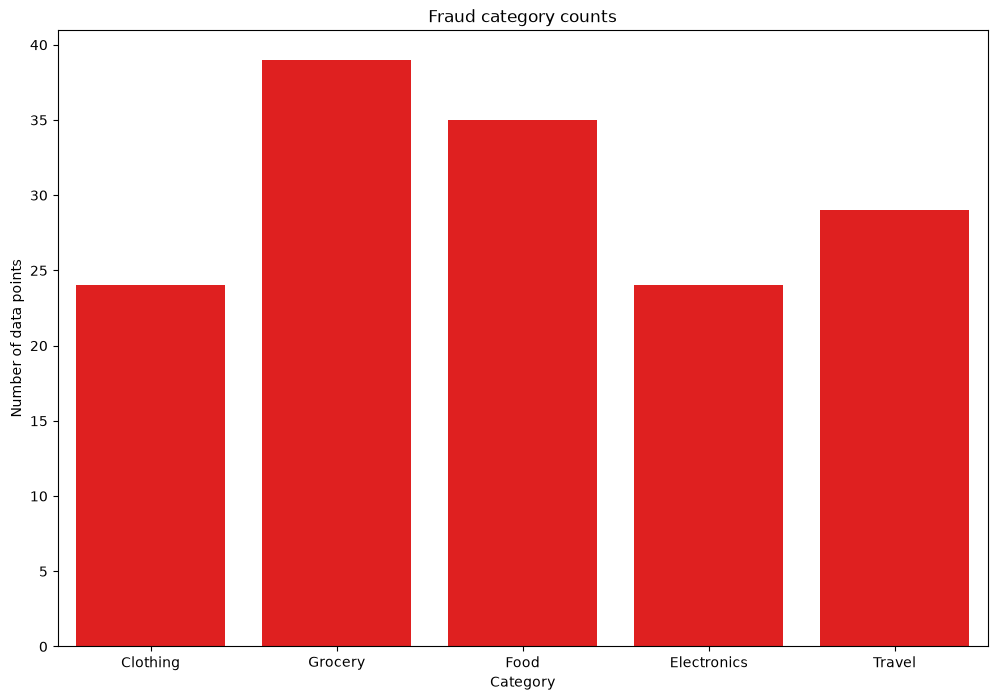

In [13]:
check_counts(
    data=data.loc[data["is_fraud"] == 1, "merchant_category"], 
    title="Fraud category counts", 
    xlabel="Category",
    color="red",
)

### Check foreign transactions

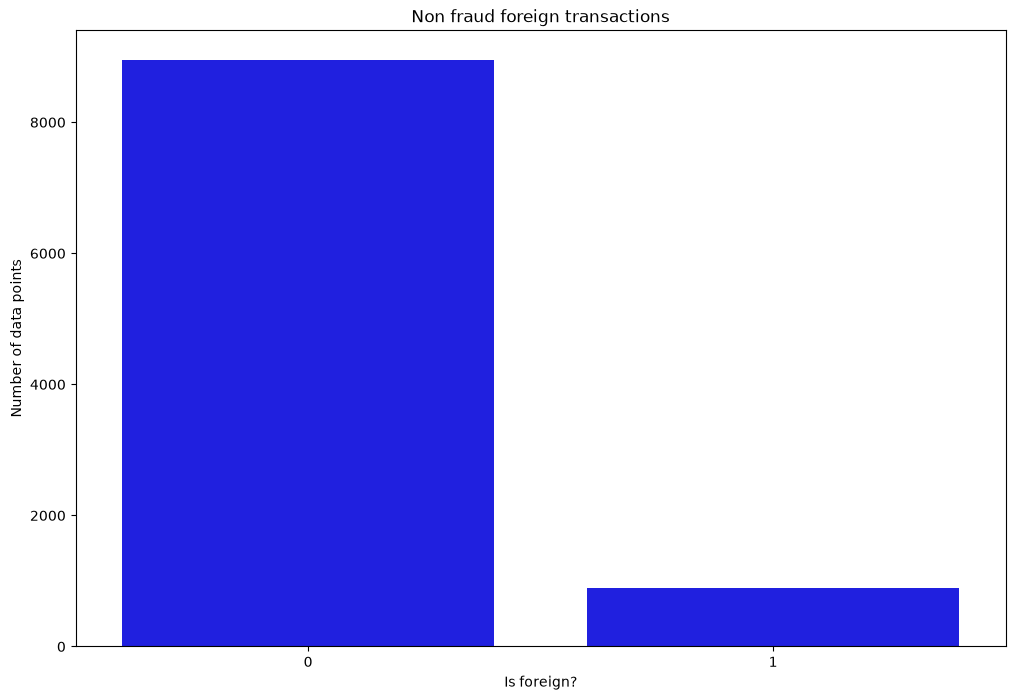

In [14]:
check_counts(
    data=data.loc[data["is_fraud"] == 0, "foreign_transaction"], 
    title="Non fraud foreign transactions", 
    xlabel="Is foreign?",
    color="blue",
)

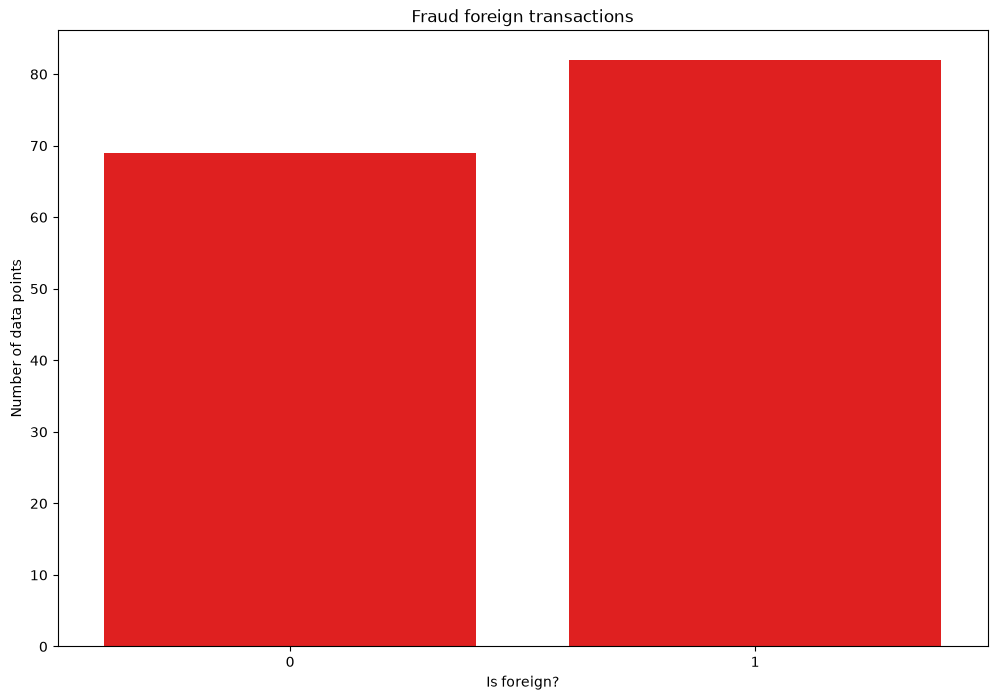

In [15]:
check_counts(
    data=data.loc[data["is_fraud"] == 1, "foreign_transaction"], 
    title="Fraud foreign transactions", 
    xlabel="Is foreign?",
    color="red",
)

### Check location mismatches

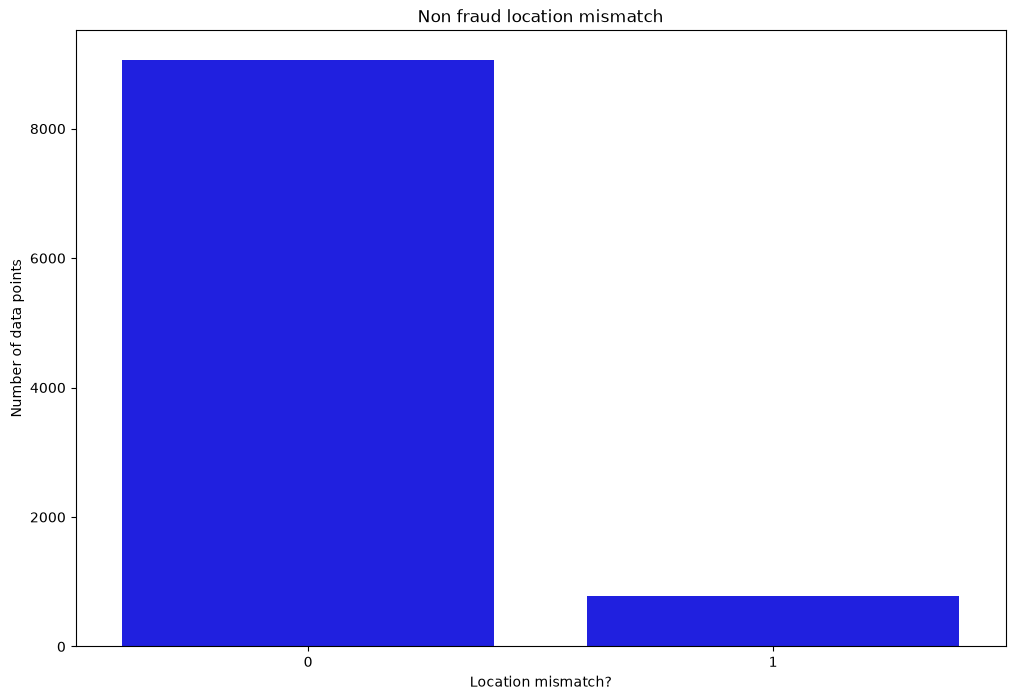

In [16]:
check_counts(
    data=data.loc[data["is_fraud"] == 0, "location_mismatch"], 
    title="Non fraud location mismatch", 
    xlabel="Location mismatch?",
    color="blue",
)

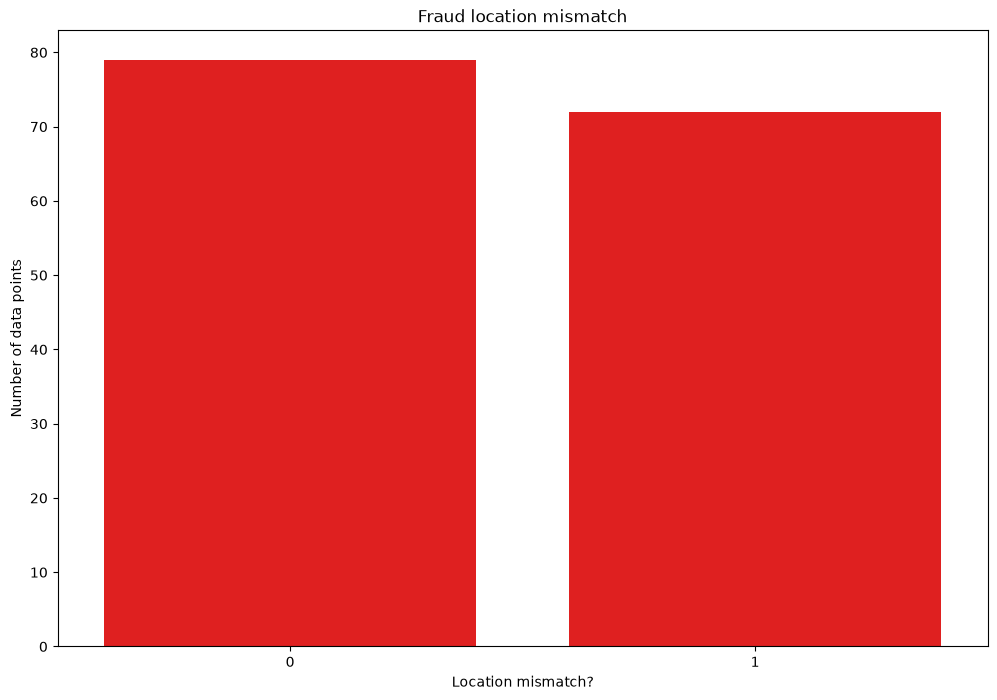

In [17]:
check_counts(
    data=data.loc[data["is_fraud"] == 1, "location_mismatch"], 
    title="Fraud location mismatch", 
    xlabel="Location mismatch?",
    color="red",
)

### Check device trust scores

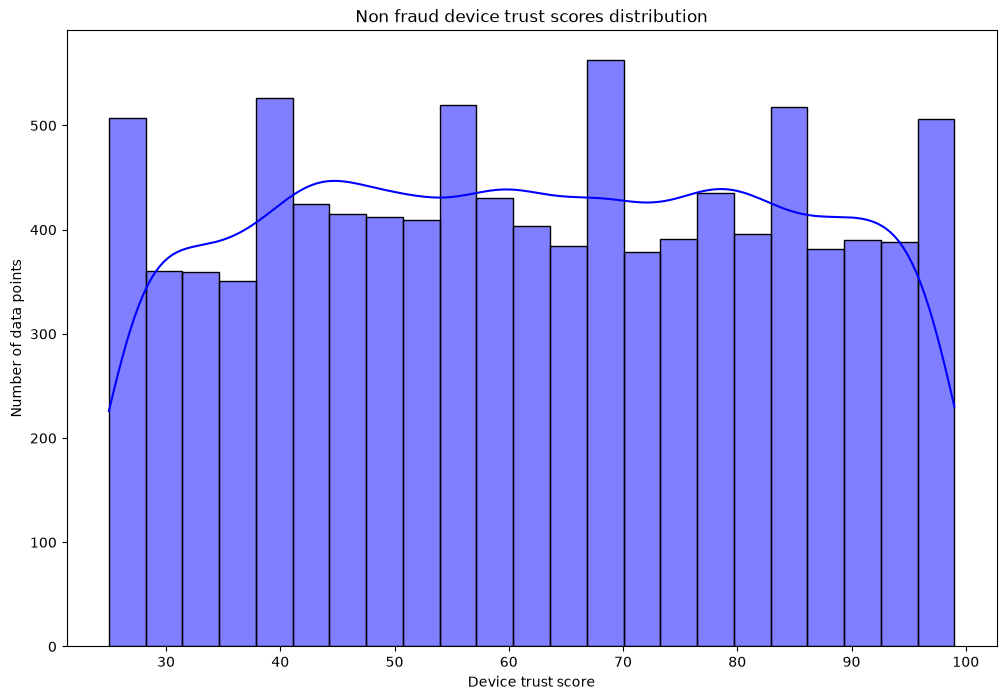

In [18]:
check_distribution(
    data=data.loc[data["is_fraud"] == 0, "device_trust_score"],
    title="Non fraud device trust scores distribution",
    xlabel="Device trust score",
    color="blue",
)

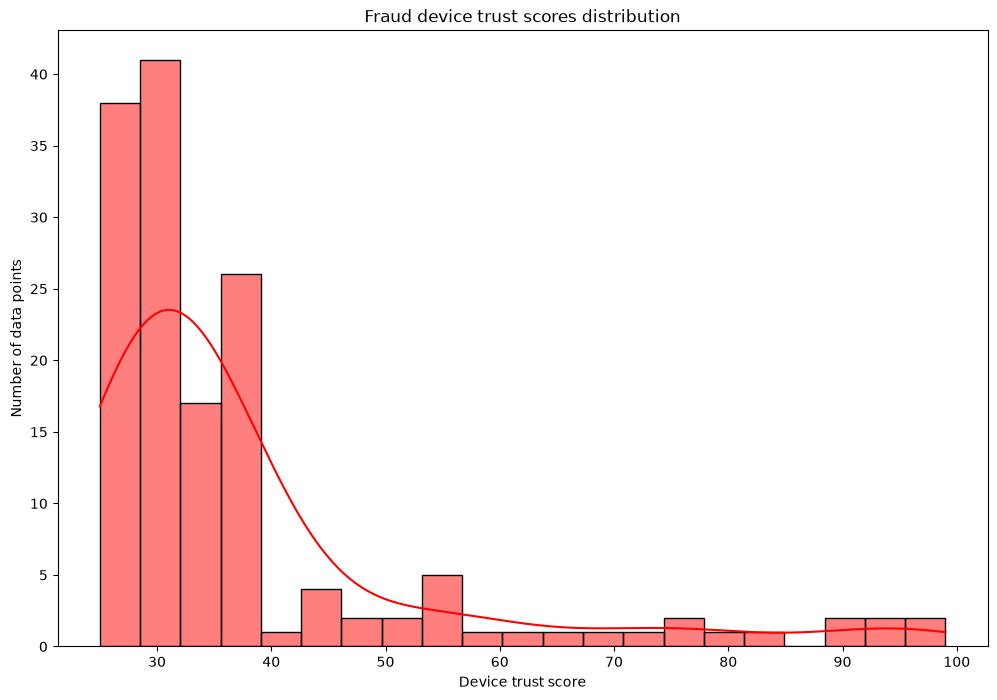

In [19]:
check_distribution(
    data=data.loc[data["is_fraud"] == 1, "device_trust_score"],
    title="Fraud device trust scores distribution",
    xlabel="Device trust score",
    color="red",
)

#### Most fraudulent transactions comes from untrustworthy devices

In [20]:
data["suspicious_device"] = (data["device_trust_score"] <= 50).astype(int)

### Check last 24h velocity

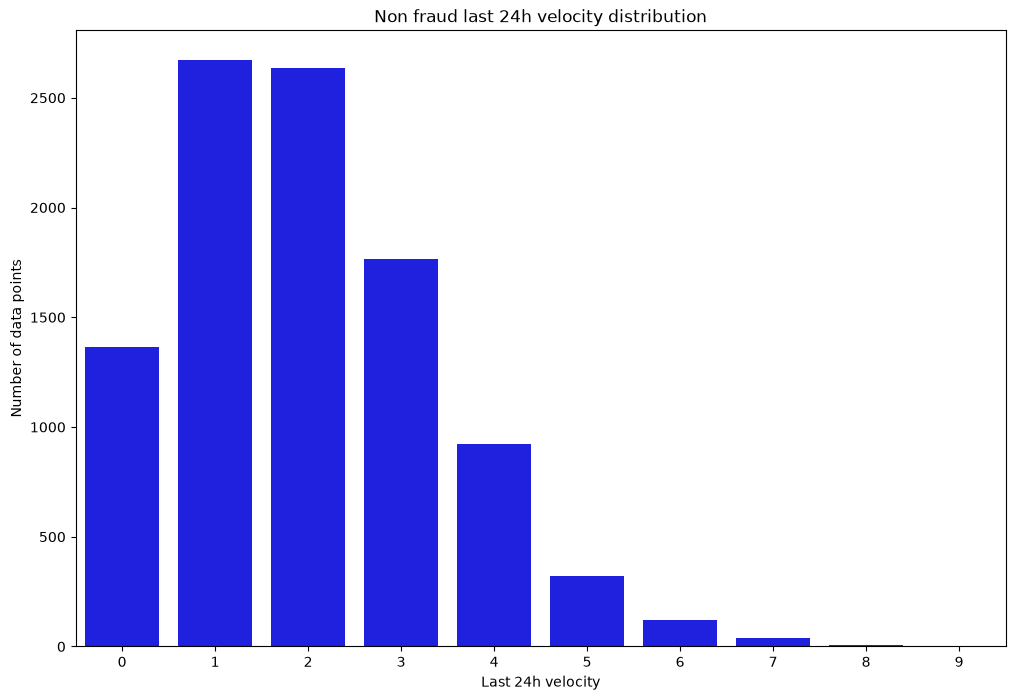

In [21]:
check_counts(
    data=data.loc[data["is_fraud"] == 0, "velocity_last_24h"],
    title="Non fraud last 24h velocity distribution",
    xlabel="Last 24h velocity",
    color="blue",
)

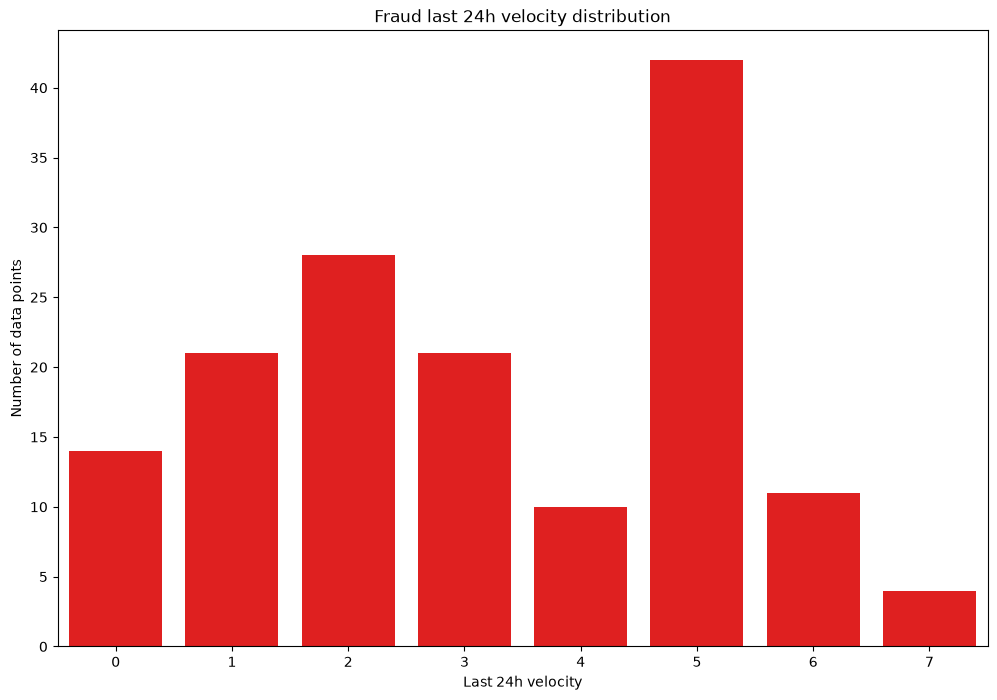

In [22]:
check_counts(
    data=data.loc[data["is_fraud"] == 1, "velocity_last_24h"],
    title="Fraud last 24h velocity distribution",
    xlabel="Last 24h velocity",
    color="red",
)

#### Fraudulent transactions tend to occur 5 or more times within 24 hours

In [23]:
data["multiple_transaction"] = (data["velocity_last_24h"] >= 5).astype(int)

### Check cardholder ages

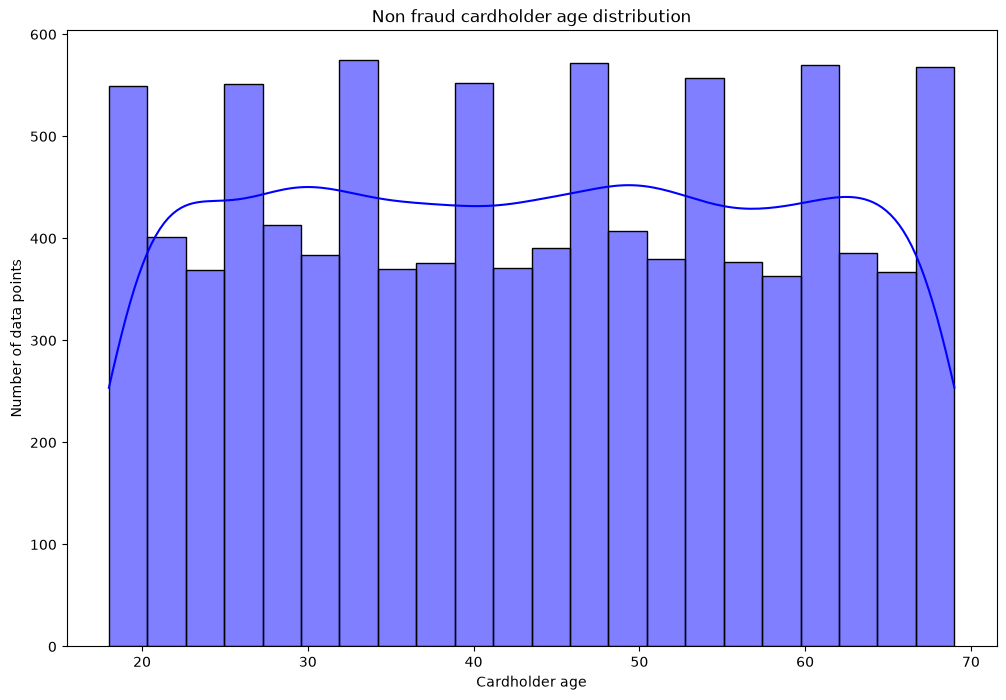

In [24]:
check_distribution(
    data=data.loc[data["is_fraud"] == 0, "cardholder_age"],
    title="Non fraud cardholder age distribution",
    xlabel="Cardholder age",
    color="blue",
)

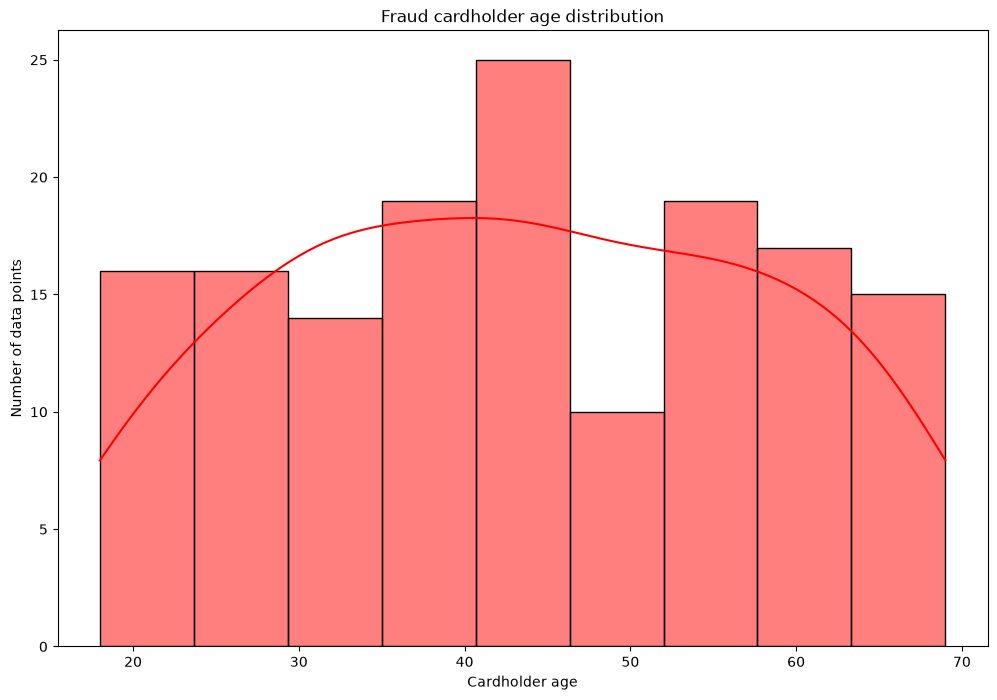

In [25]:
check_distribution(
    data=data.loc[data["is_fraud"] == 1, "cardholder_age"],
    title="Fraud cardholder age distribution",
    xlabel="Cardholder age",
    color="red",
)

### Check target class counts

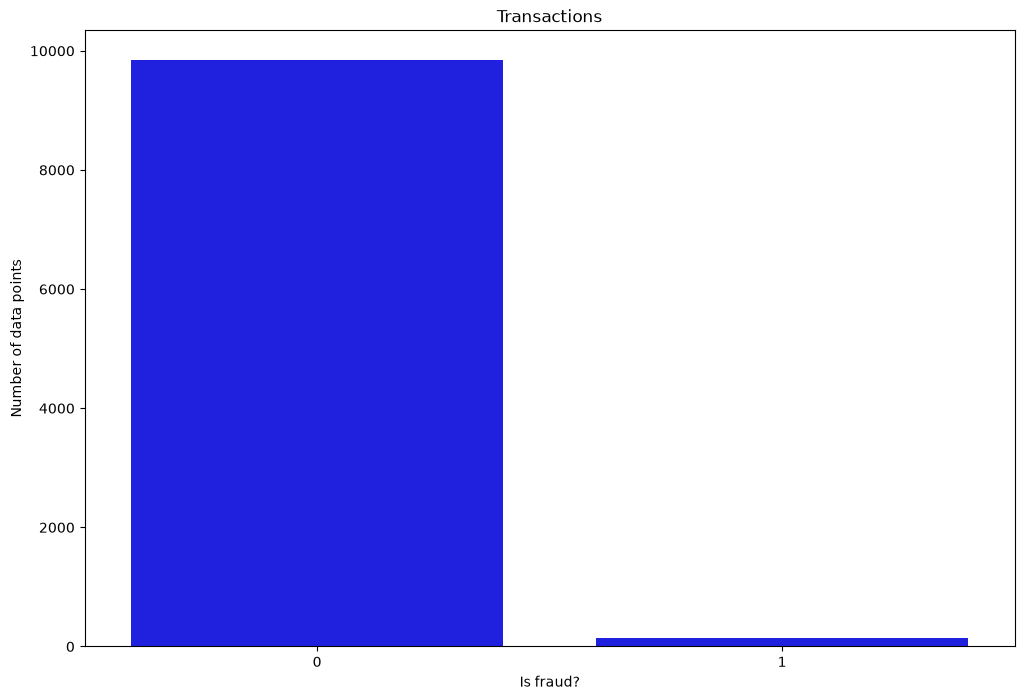

In [26]:
check_counts(
    data=data["is_fraud"],
    title="Transactions",
    xlabel="Is fraud?",
    color="blue",
)

## ML models training

#### Prepare data

In [27]:
num_cols = ["amount","transaction_hour","device_trust_score","velocity_last_24h","cardholder_age"]
cat_cols = ["merchant_category","foreign_transaction","location_mismatch","nighttime_transaction", 
            "suspicious_device", "multiple_transaction"]

X = data.drop(columns=["is_fraud"])
y = data["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=8)

### Logistic Regression

#### Build pipeline

In [28]:
preprocessor = ColumnTransformer([
        ("num",StandardScaler(), num_cols),
        ("cat",OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="passthrough"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=8)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=8)),
])

param_dist = {
    # SMOTE
    "smote__sampling_strategy": ["auto", "minority", "not majority"],
    "smote__k_neighbors": range(1, 10),

    # Logistic Regression
    "classifier__C": loguniform(1e-3, 1e3),
    "classifier__solver": ["liblinear", "lbfgs"],
    "classifier__class_weight": [None, "balanced"],
}

#### Find best hyperparams

In [29]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=8,
)

search = RandomizedSearchCV(
    pipeline,
    param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=8,
)

search.fit(X_train, y_train)

# Best hyperparams and score
print("Best parameters:")
print(search.best_params_)

print("\nBest CV F1-macro:")
print(search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'classifier__C': np.float64(696.8373928334253), 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs', 'smote__k_neighbors': 3, 'smote__sampling_strategy': 'not majority'}

Best CV F1-macro:
0.8400141082477142


#### Evaluate

Accuracy     : 0.9856666666666667
Precision    : 0.5434782608695652
Recall       : 0.9803921568627451
F1-score     : 0.6993006993006993
ROC-AUC score: 0.9830750204456147
Classification report:

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2949
           1       0.54      0.98      0.70        51

    accuracy                           0.99      3000
   macro avg       0.77      0.98      0.85      3000
weighted avg       0.99      0.99      0.99      3000



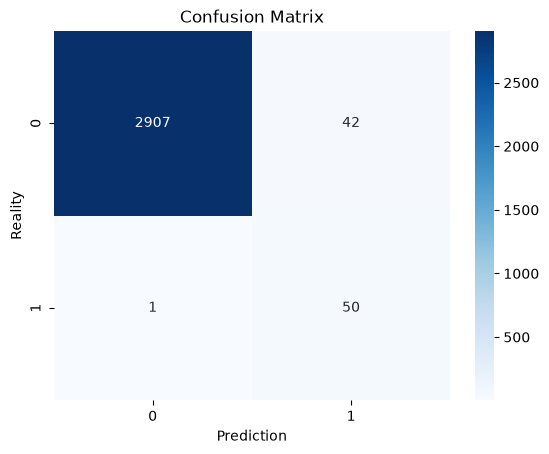

In [30]:
lr_clf = search.best_estimator_

y_pred = lr_clf.predict(X_test)

print("Accuracy     :", accuracy_score(y_test, y_pred))
print("Precision    :", precision_score(y_test, y_pred))
print("Recall       :", recall_score(y_test, y_pred))
print("F1-score     :", f1_score(y_test, y_pred))
print("ROC-AUC score:", roc_auc_score(y_test, y_pred))
print("Classification report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediction")
plt.ylabel("Reality")
plt.title("Confusion Matrix")
plt.show()

### Random Forest

#### Build pipeline

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=8)),
    ("classifier", RandomForestClassifier(random_state=8)),
])

param_dist = {
    # SMOTE
    "smote__sampling_strategy": ["auto", "minority", "not majority"],
    "smote__k_neighbors": range(1, 10),

    # Random Forest
    "classifier__n_estimators": [50, 60, 70, 80, 90, 100, 110, 120],
    "classifier__max_depth": [None, 10, 20, 30, 40, 50, 60],
    "classifier__min_samples_leaf": [1, 2, 3],
    "classifier__min_samples_split": [2, 3, 4, 5, 6, 7],
    "classifier__max_features": [1.0, "sqrt", "log2"]
}

#### Find best hyperparams

In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=8,
)

search = RandomizedSearchCV(
    pipeline,
    param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=8,
)

search.fit(X_train, y_train)

# Best hyperparams and score
print("Best parameters:")
print(search.best_params_)

print("\nBest CV F1-macro:")
print(search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'smote__sampling_strategy': 'minority', 'smote__k_neighbors': 7, 'classifier__n_estimators': 70, 'classifier__min_samples_split': 3, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 20}

Best CV F1-macro:
0.9474934408687965


#### Evaluate

Accuracy     : 0.995
Precision    : 0.86
Recall       : 0.8431372549019608
F1-score     : 0.8514851485148515
ROC-AUC score: 0.9203817844533541
Classification report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2949
           1       0.86      0.84      0.85        51

    accuracy                           0.99      3000
   macro avg       0.93      0.92      0.92      3000
weighted avg       0.99      0.99      0.99      3000



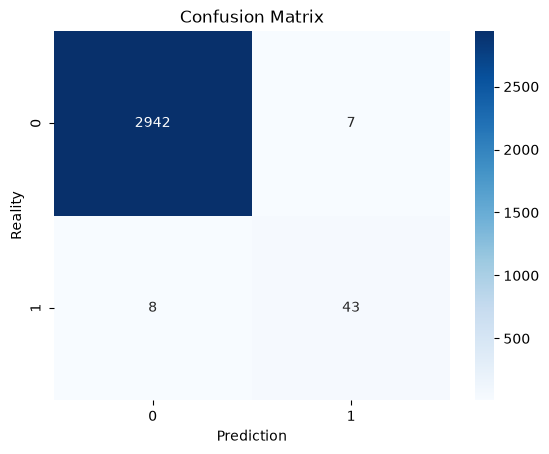

In [33]:
rf_clf = search.best_estimator_

y_pred = rf_clf.predict(X_test)

print("Accuracy     :", accuracy_score(y_test, y_pred))
print("Precision    :", precision_score(y_test, y_pred))
print("Recall       :", recall_score(y_test, y_pred))
print("F1-score     :", f1_score(y_test, y_pred))
print("ROC-AUC score:", roc_auc_score(y_test, y_pred))
print("Classification report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediction")
plt.ylabel("Reality")
plt.title("Confusion Matrix")
plt.show()

### XGBoost

#### Build pipeline

In [34]:
preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ], remainder="passthrough"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=8)),
    ("classifier", XGBClassifier(
        random_state=8,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=1,
    )),
])

param_dist = {
    # SMOTE
    "smote__sampling_strategy": ["auto", "minority", "not majority"],
    "smote__k_neighbors": range(1, 10),

    # XGBoost
    "classifier__n_estimators": randint(100, 600),
    "classifier__max_depth": randint(3, 11),
    "classifier__learning_rate": loguniform(0.01, 0.3),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree": uniform(0.6, 0.4),
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 5),
    "classifier__reg_alpha": loguniform(1e-4, 10),
    "classifier__reg_lambda": loguniform(1e-3, 100),
}

#### Find best hyperparameters

In [35]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=8,
)

search = RandomizedSearchCV(
    pipeline,
    param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=8,
)

search.fit(X_train, y_train)

# Best hyperparams and score
print("Best parameters:")
print(search.best_params_)

print("\nBest CV F1-macro:")
print(search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'classifier__colsample_bytree': np.float64(0.8335858174003867), 'classifier__gamma': np.float64(0.19456148821160923), 'classifier__learning_rate': np.float64(0.045647896045325355), 'classifier__max_depth': 9, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 415, 'classifier__reg_alpha': np.float64(0.0011928586861882087), 'classifier__reg_lambda': np.float64(0.005686571947514156), 'classifier__subsample': np.float64(0.8144577226718298), 'smote__k_neighbors': 8, 'smote__sampling_strategy': 'auto'}

Best CV F1-macro:
0.9785961165885084


#### Evaluate

Accuracy     : 0.9993333333333333
Precision    : 1.0
Recall       : 0.9607843137254902
F1-score     : 0.98
ROC-AUC score: 0.9803921568627452
Classification report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2949
           1       1.00      0.96      0.98        51

    accuracy                           1.00      3000
   macro avg       1.00      0.98      0.99      3000
weighted avg       1.00      1.00      1.00      3000



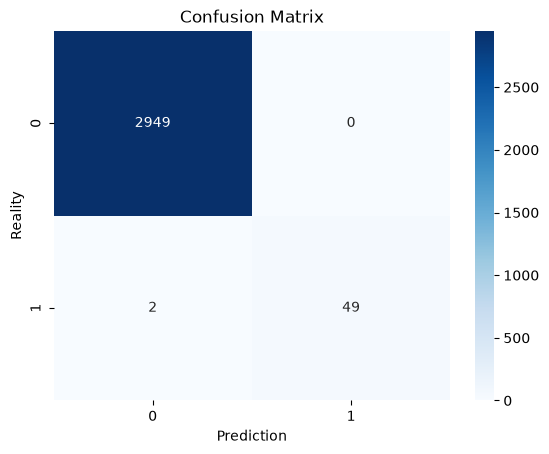

In [36]:
xg_clf = search.best_estimator_

y_pred = xg_clf.predict(X_test)

print("Accuracy     :", accuracy_score(y_test, y_pred))
print("Precision    :", precision_score(y_test, y_pred))
print("Recall       :", recall_score(y_test, y_pred))
print("F1-score     :", f1_score(y_test, y_pred))
print("ROC-AUC score:", roc_auc_score(y_test, y_pred))
print("Classification report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediction")
plt.ylabel("Reality")
plt.title("Confusion Matrix")
plt.show()

### Test models on single samples

In [37]:
non_fraud_sample = pd.DataFrame([{
    "amount": 400.0,
    "transaction_hour": 11,
    "merchant_category": "Food",
    "foreign_transaction": 0,
    "location_mismatch": 0,
    "device_trust_score": 90,
    "velocity_last_24h": 3,
    "cardholder_age": 25,
    "nighttime_transaction": 0,
    "suspicious_device": 0,
    "multiple_transaction": 0,
}])

fraud_sample = pd.DataFrame([{
    "amount": 40.0,
    "transaction_hour": 3,
    "merchant_category": "Grocery",
    "foreign_transaction": 1,
    "location_mismatch": 1,
    "device_trust_score": 20,
    "velocity_last_24h": 7,
    "cardholder_age": 37,
    "nighttime_transaction": 1,
    "suspicious_device": 1,
    "multiple_transaction": 1,
}])

print("Logistic Regression Classifier")
print(f"Non fraud detection: {lr_clf.predict(non_fraud_sample)[0]}")
print(f"Fraud detection: {lr_clf.predict(fraud_sample)[0]}")

print("\nRandom Forest Classifier")
print(f"Non fraud detection: {rf_clf.predict(non_fraud_sample)[0]}")
print(f"Fraud detection: {rf_clf.predict(fraud_sample)[0]}")

print("\nXGBoost Classifier")
print(f"Non fraud detection: {xg_clf.predict(non_fraud_sample)[0]}")
print(f"Fraud detection: {xg_clf.predict(fraud_sample)[0]}")

Logistic Regression Classifier
Non fraud detection: 0
Fraud detection: 1

Random Forest Classifier
Non fraud detection: 0
Fraud detection: 1

XGBoost Classifier
Non fraud detection: 0
Fraud detection: 1


### Save best models

In [38]:
with open("credit_card_fraud_detector.pkl", "wb") as file:
    pickle.dump(xg_clf, file)